# Practice 2 — ADF and ARIMA

Notebook core cho E01–E05 trên Monthly anti-diabetic drug sales in Australia (`a10.csv`), từ 1991-07 đến 2008-06.

Mỗi exercise được tổ chức theo Markdown → code → interpretation. E04/E05 hiện ở trạng thái reconciliation và không phải completion evidence.

In [1]:
import logging
import os
import numpy as np

import pandas as pd
from IPython.display import Image, display
from practice_2 import find_practice_root
from practice_2.analysis import (
    acf_pacf_tables,
    evaluate_forecast,
    fit_arima,
    fit_sarimax,
    forecast_model,
    inverse_log_forecast,
    residual_diagnostics,
    residual_summary,
    seasonal_naive_forecast,
    validate_forecast_alignment,
)
from practice_2.data import chronological_split, load_monthly_retail_sales
from practice_2.analysis.stationarity import log_first_difference, run_adf
from practice_2.visualization.table_style import style_table
from practice_2.visualization.plots import (
    save_acf_pacf_plot,
    save_forecast_comparison_plot,
    save_residual_diagnostics_plot,
)

PROJECT_ROOT = find_practice_root()
RAW_PATH = PROJECT_ROOT / "datasets" / "raw" / "a10.csv"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"
RUN_ID = os.environ.get("PRACTICE_2_RUN_ID", "manual_run")
RUN_ID = "".join(char if char.isalnum() or char in "-_" else "_" for char in RUN_ID)
RUNS_DIR = PROJECT_ROOT / "runs"
LOG_DIR = RUNS_DIR / RUN_ID
for folder in [FIGURES_DIR, RESULTS_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
print("Core imports and paths initialized.")


Core imports and paths initialized.


## 0. Setup, paths và logging

In [2]:
from pathlib import Path

LOG_DIR.mkdir(parents=True, exist_ok=True)
LOG_PATH = LOG_DIR / "Practice_2_Exercise.log"

logging.basicConfig(
    filename=LOG_PATH,
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    encoding="utf-8",
    force=True,
)

logging.info("Practice 2 initialized.")
logging.info("Logging system configured successfully.")
logging.info("Run ID: %s", RUN_ID)
print(f"Log file created at: {LOG_PATH}")


Log file created at: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/runs/manual_run/Practice_2_Exercise.log


## 1. E01 — Khám phá dữ liệu và chuẩn bị time series
<a id="exercise-1"></a>

### Kiểm tra dữ liệu trước

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df = pd.read_csv(RAW_PATH, parse_dates=["date"])

# Sắp xếp theo thời gian và đưa date thành index
df = df.sort_values("date").set_index("date")

# Kiểm tra thông tin dữ liệu
print(df.info())
print("\n5 dòng đầu:")
print(df.head())

<class 'pandas.DataFrame'>
DatetimeIndex: 204 entries, 1991-07-01 to 2008-06-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   204 non-null    float64
dtypes: float64(1)
memory usage: 3.2 KB
None

5 dòng đầu:
               value
date                
1991-07-01  3.526591
1991-08-01  3.180891
1991-09-01  3.252221
1991-10-01  3.611003
1991-11-01  3.565869


In [4]:
print("\\nThống kê mô tả:")
print(df["value"].describe())

expected_index = pd.date_range(start=df.index.min(), end=df.index.max(), freq="MS")
validation = pd.DataFrame({
    "metric": ["rows", "start", "end", "index_type", "frequency", "missing_values", "duplicate_timestamps", "missing_intervals", "chronological"],
    "value": [len(df), df.index.min(), df.index.max(), type(df.index).__name__, df.index.freqstr, int(df["value"].isna().sum()), int(df.index.has_duplicates), len(expected_index.difference(df.index)), df.index.is_monotonic_increasing],
})
logging.info(f"Hoàn thành kiểm tra dữ liệu | Số quan sát: {len(df)} | Giá trị thiếu: {df["value"].isna().sum()}")
display(style_table(validation, caption="E01 — Kiểm tra tính toàn vẹn dữ liệu"))


\nThống kê mô tả:
count    204.000000
mean      10.694430
std        5.956998
min        2.814520
25%        5.844095
50%        9.319345
75%       14.289964
max       29.665356
Name: value, dtype: float64


metric,value
rows,204
start,1991-07-01 00:00:00
end,2008-06-01 00:00:00
index_type,DatetimeIndex
frequency,None
missing_values,0
duplicate_timestamps,0
missing_intervals,0
chronological,True


In [5]:
import numpy as np
import pandas as pd

series = df["value"].copy()
series = pd.to_numeric(series, errors="coerce")
series = series.dropna()

mean_value = series.mean()
median_value = series.median()
std_value = series.std()
variance_value = series.var()

cv = (
    std_value / mean_value * 100
    if mean_value != 0 else np.nan
)

skewness = series.skew()
kurtosis = series.kurt()

start_value = float(series.iloc[0])
end_value = float(series.iloc[-1])

absolute_change = end_value - start_value

percentage_change = (
    (end_value / start_value - 1) * 100
    if start_value != 0 else np.nan
)

# CAGR: tốc độ tăng trưởng kép bình quân năm
if isinstance(series.index, pd.DatetimeIndex):
    elapsed_years = (
        (series.index[-1] - series.index[0]).days / 365.2425
    )
else:
    elapsed_years = np.nan

cagr = (
    ((end_value / start_value) ** (1 / elapsed_years) - 1) * 100
    if pd.notna(elapsed_years)
    and elapsed_years > 0
    and start_value > 0
    and end_value > 0
    else np.nan
)

# Mức thay đổi theo tháng
monthly_change = series.diff().dropna()
monthly_pct_change = series.pct_change().dropna() * 100

max_monthly_increase = monthly_change.max()
max_monthly_decrease = monthly_change.min()

max_monthly_growth = monthly_pct_change.max()
max_monthly_decline = monthly_pct_change.min()

# Tự tương quan
autocorr_1 = series.autocorr(lag=1)
autocorr_12 = (
    series.autocorr(lag=12)
    if len(series) > 12 else np.nan
)

# Phát hiện ngoại lệ bằng quy tắc IQR
q1, q3 = series.quantile([0.25, 0.75])
iqr = q3 - q1

potential_outliers = series[
    (series < q1 - 1.5 * iqr) |
    (series > q3 + 1.5 * iqr)
]

outlier_count = len(potential_outliers)
outlier_percentage = outlier_count / len(series) * 100

# Tổng hợp các chỉ số
additional_metrics = pd.DataFrame({
    "metric": [
        "median",
        "variance",
        "coefficient_of_variation_pct",
        "skewness",
        "kurtosis",
        "absolute_change",
        "percentage_change_pct",
        "cagr_pct",
        "max_monthly_increase",
        "max_monthly_decrease",
        "max_monthly_growth_pct",
        "max_monthly_decline_pct",
        "autocorrelation_lag_1",
        "autocorrelation_lag_12",
        "potential_outlier_count",
        "potential_outlier_percentage"
    ],
    "value": [
        median_value,
        variance_value,
        cv,
        skewness,
        kurtosis,
        absolute_change,
        percentage_change,
        cagr,
        max_monthly_increase,
        max_monthly_decrease,
        max_monthly_growth,
        max_monthly_decline,
        autocorr_1,
        autocorr_12,
        outlier_count,
        outlier_percentage
    ]
})

display(additional_metrics)


,metric,value
0,median,9.319345
1,variance,35.485823
2,coefficient_of_variation_pct,55.701875
3,skewness,0.843794
4,kurtosis,0.028921
5,absolute_change,15.905149
6,percentage_change_pct,451.006340
7,cagr_pct,10.612165
8,max_monthly_increase,4.842732
9,max_monthly_decrease,-11.274514


### Biểu đồ chuỗi thời gian

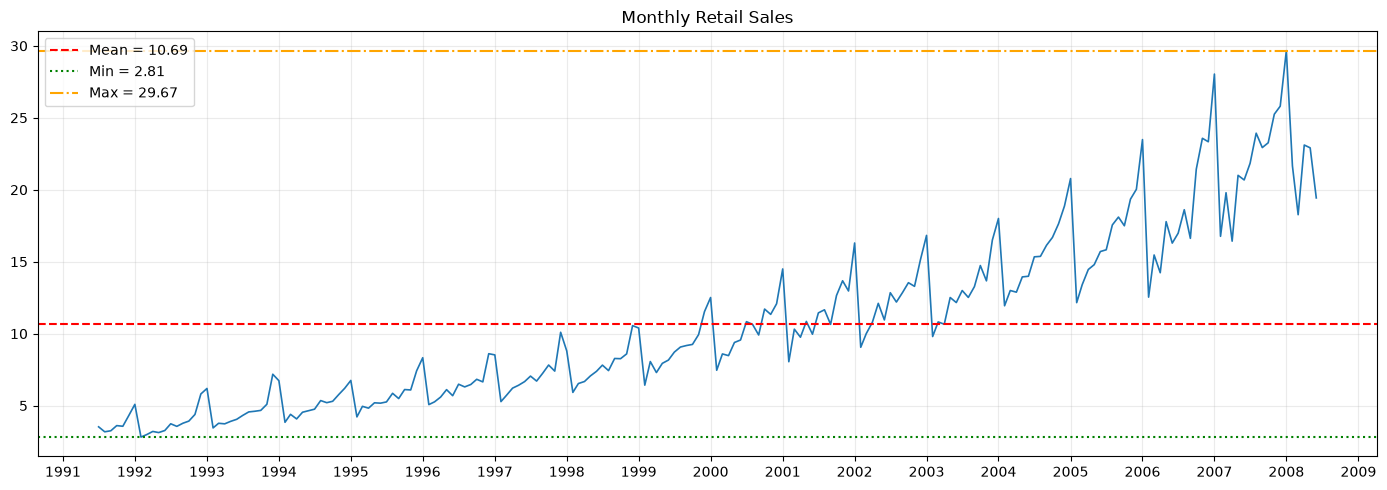

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Đọc dữ liệu
df = pd.read_csv(
    RAW_PATH,
    parse_dates=["date"]
)

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df["date"],
    df["value"],
    linewidth=1.2
)

# Tiêu đề
ax.set_title("Monthly Retail Sales")

# Tính giá trị Mean, Min, Max
mean_value = df["value"].mean()
min_value = df["value"].min()
max_value = df["value"].max()
# Đường Mean
ax.axhline(
    y=mean_value,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean = {mean_value:.2f}"
)
# Đường Min
ax.axhline(
    y=min_value,
    color="green",
    linestyle=":",
    linewidth=1.5,
    label=f"Min = {min_value:.2f}"
)
# Đường Max
ax.axhline(
    y=max_value,
    color="orange",
    linestyle="-.",
    linewidth=1.5,
    label=f"Max = {max_value:.2f}"
)

# Hiển thị năm trên trục X, cách nhau YearLocator
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(True, alpha=0.25)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()


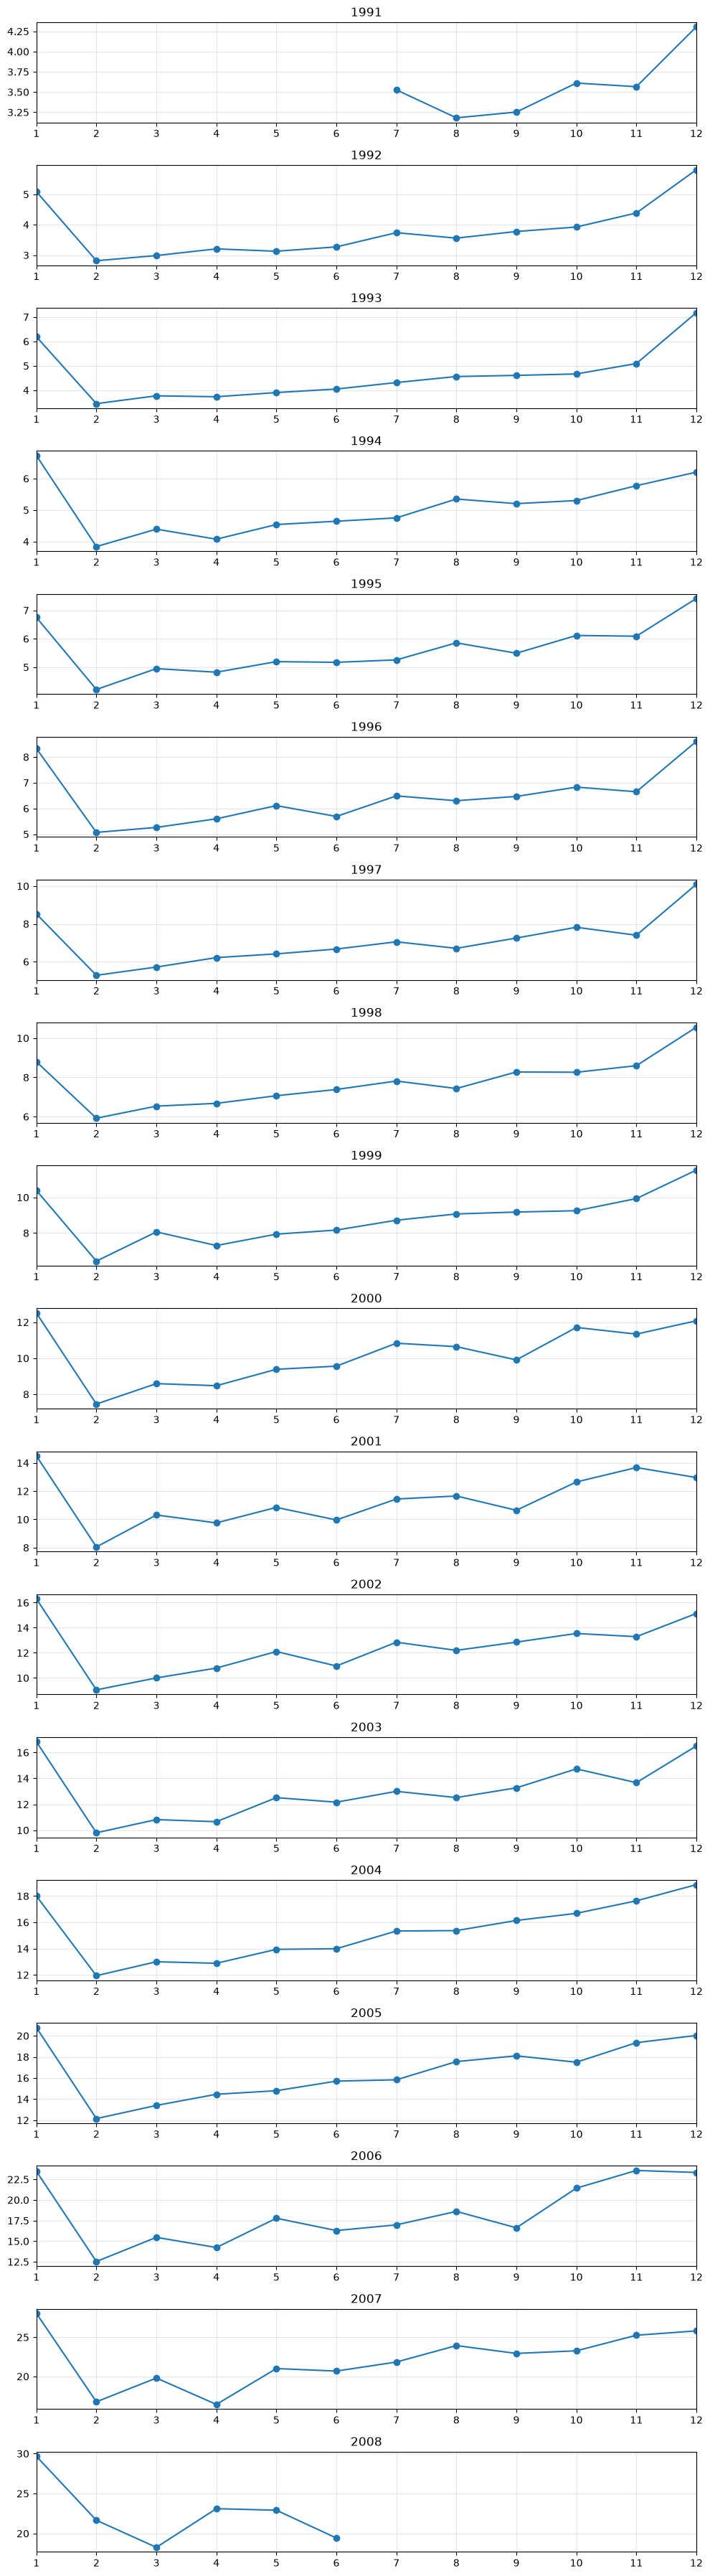

In [7]:

import pandas as pd
from matplotlib import pyplot as plt

df = pd.read_csv(RAW_PATH, header=0, parse_dates=["date"])

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

years = df.pivot(index="month", columns="year", values="value")

fig, axes = plt.subplots(
    nrows=len(years.columns),
    ncols=1,
    figsize=(10, 2 * len(years.columns)),
    squeeze=False
)

for ax, year in zip(axes[:, 0], years.columns):
    ax.plot(years.index, years[year], marker="o")
    ax.set_title(str(year))
    ax.set_xticks(range(1, 13))
    ax.set_xlim(1, 12)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


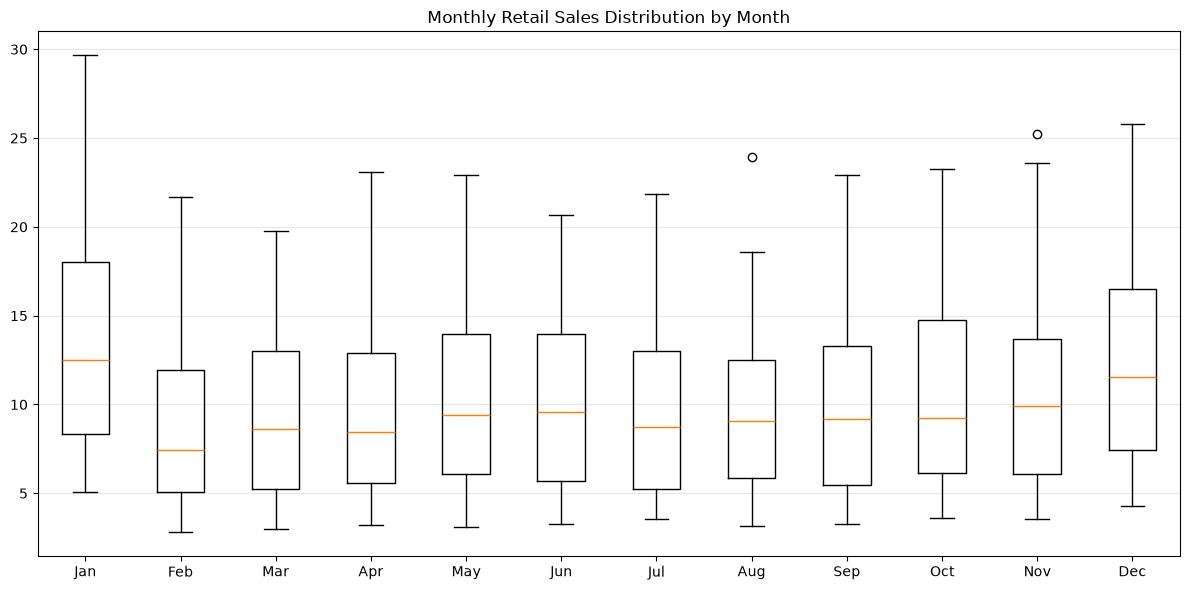

In [8]:
from pandas import read_csv
from matplotlib import pyplot

# Đọc dữ liệu
series = read_csv(
    RAW_PATH,
    header=0,
    parse_dates=["date"],
    index_col="date"
)["value"]

monthly_data = [
    series[series.index.month == month].dropna().values
    for month in range(1, 13)
]

# Vẽ Boxplot
pyplot.figure(figsize=(12, 6))

pyplot.boxplot(
    monthly_data,
    tick_labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)

pyplot.title("Monthly Retail Sales Distribution by Month")
pyplot.grid(axis="y", alpha=0.3)

pyplot.tight_layout()
pyplot.show()


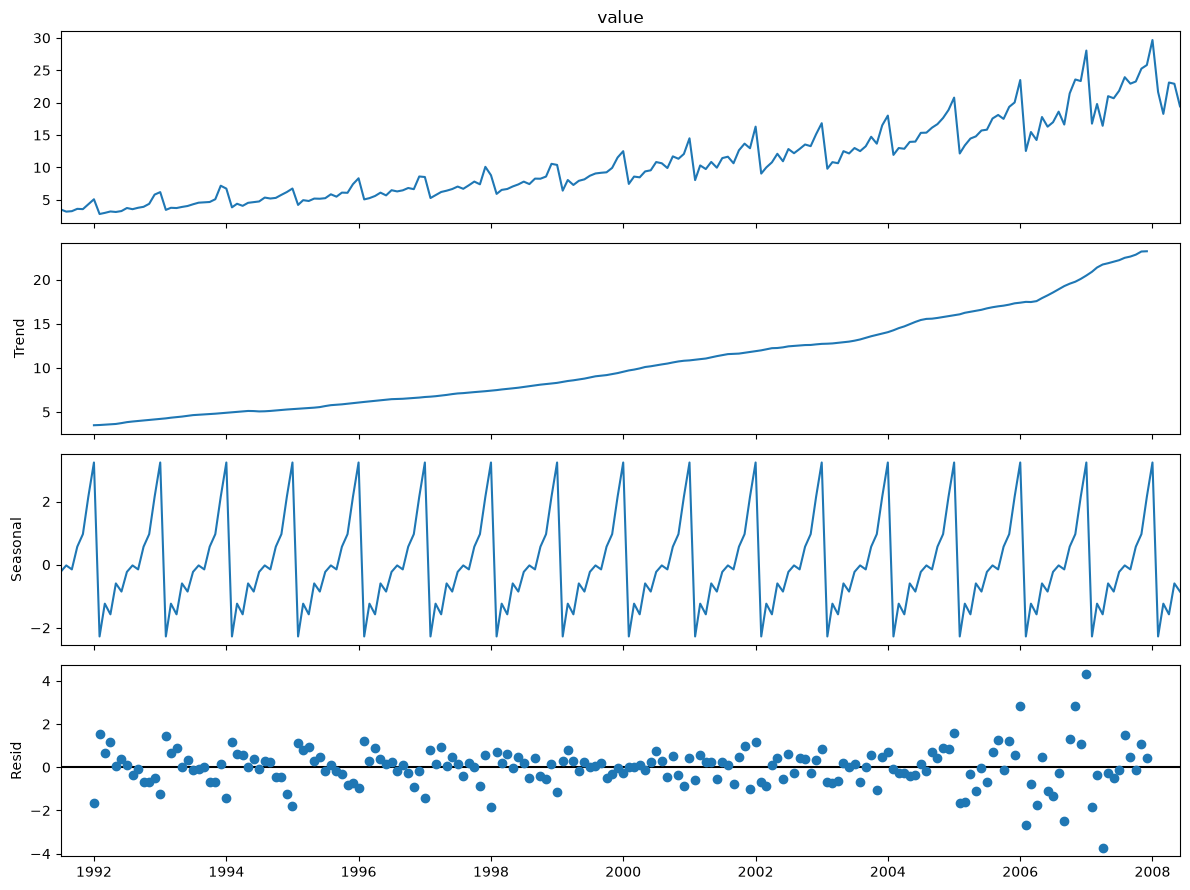

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(
    series,
    model="additive",
    period=12
)

fig = result.plot()
fig.set_size_inches(12, 9)
plt.tight_layout()
plt.show()


## 2. E02 — Kiểm định ADF trên chuỗi gốc
<a id="exercise-2"></a>

### 1. Kiểm định ADF

**H₀:** chuỗi có unit root. Ngưỡng kiểm định: `α = 0.05`.

### 2. Historical execution note

E02 hiện đã được chạy lại trên đúng 163 observations training; evidence được ghi ở execution log, còn formal status vẫn chờ approval reconciliation.

In [10]:
series = load_monthly_retail_sales(RAW_PATH)
train, test = chronological_split(series, train_fraction=0.8)
log_train = pd.Series(np.log(train.astype(float)), index=train.index, name="log_value")

split_summary = pd.DataFrame({
    "Partition": ["Train", "Test"],
    "Observations": [len(train), len(test)],
    "Start": [train.index.min(), test.index.min()],
    "End": [train.index.max(), test.index.max()],
    "Protocol status": ["Used for E02–E05 fitting", "Sealed until E05"],
})

def highlight_split_status(row):
    if row["Protocol status"] == "Sealed until E05":
        return ["background-color: #dbeafe; font-weight: 600"] * len(row)
    return ["background-color: #dcfce7; color: #166534"] * len(row)

display(style_table(
    split_summary,
    caption="E01 — Chronological boundary declared before downstream analysis",
    formats={"Observations": "{:,}", "Start": "{:%Y-%m}", "End": "{:%Y-%m}"},
    row_highlighter=highlight_split_status,
))

adf_train, adf_critical = run_adf(train)
adf_display = adf_train.assign(Series="Original training series")[["Series", "metric", "value"]]
display(style_table(
    adf_display,
    caption="E02 — ADF on original training series (n=163)",
))
logging.info("E02 train-only ADF complete | n_train=%d | n_test=%d", len(train), len(test))


Partition,Observations,Start,End,Protocol status
Train,163,1991-07,2005-01,Used for E02–E05 fitting
Test,41,2005-02,2008-06,Sealed until E05


/Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/src/practice_2/analysis/stationarity.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, regression="c", autolag="AIC")


Series,metric,value
Original training series,adf_statistic,2.230893
Original training series,p_value,0.998907
Original training series,used_lag,14
Original training series,n_observations,148
Original training series,alpha,0.050000
Original training series,decision,fail to reject H0


### 3. Trạng thái E02

E02 train-only evidence đã được xác nhận trong reconciliation run; formal completion vẫn chờ status approval.

## 3. E03 — Sai phân và kiểm định lại
<a id="exercise-3"></a>

### Sai phân bậc 1

In [11]:
log_diff_train = log_first_difference(train)
print("Transformation: natural_log")
print("Differencing order candidate: d=1")
print("Transformed observations:", len(log_diff_train))
logging.info("E03 transformed training series created | natural_log + first_difference | n=%d", len(log_diff_train))


Transformation: natural_log
Differencing order candidate: d=1
Transformed observations: 162


### Đồ thị chuỗi sau khi sai phân bậc 1

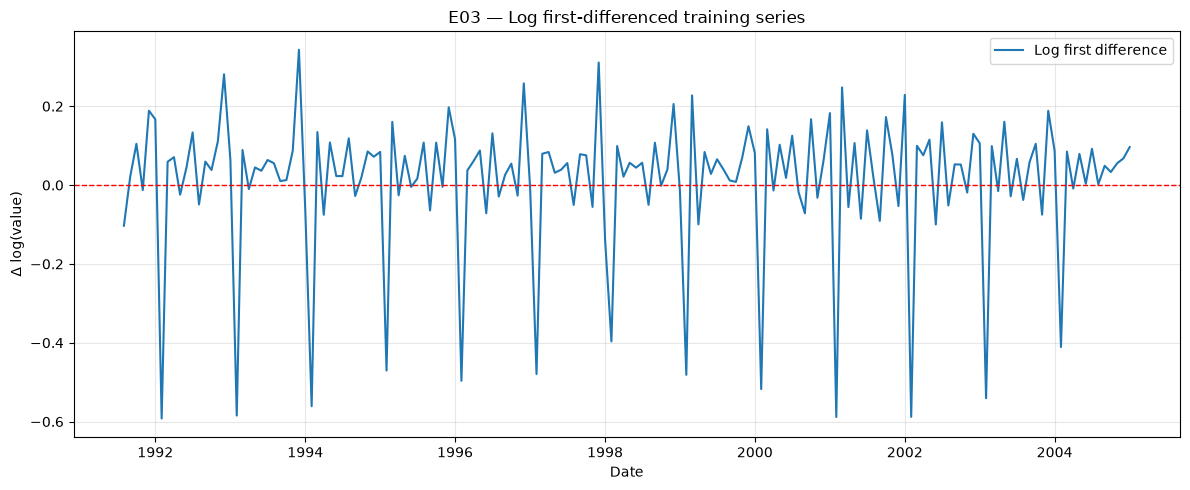

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(log_diff_train.index, log_diff_train.values, label="Log first difference")
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.title("E03 — Log first-differenced training series")
plt.xlabel("Date")
plt.ylabel("Δ log(value)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Kiểm định ADF sau sai phân bậc 1

In [13]:
adf_log_diff, adf_log_critical = run_adf(log_diff_train)
adf_log_display = adf_log_diff.assign(Series="Log first-difference training series")[["Series", "metric", "value"]]
display(style_table(
    adf_log_display,
    caption="E03 — ADF on log-first-difference training series",
))
print("Official E03 conclusion: natural log + first difference, d=1")
logging.info("E03 official conclusion | natural_log + d=1 | test_used=false")


/Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/src/practice_2/analysis/stationarity.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, regression="c", autolag="AIC")


Series,metric,value
Log first-difference training series,adf_statistic,-3.659486
Log first-difference training series,p_value,0.004720
Log first-difference training series,used_lag,13
Log first-difference training series,n_observations,148
Log first-difference training series,alpha,0.050000
Log first-difference training series,decision,reject H0


Official E03 conclusion: natural log + first difference, d=1


Vì \(0.1167 > 0.05\), ta chưa bác bỏ giả thuyết \(H_0\). Nghĩa là chưa đủ bằng chứng thống kê để kết luận chuỗi sau sai phân bậc 1 đã dừng và ADF Statistic là \(-2.4952\), lớn hơn Critical Value \(-2.8771\) (ít âm hơn), nên kết quả cũng cho cùng kết luận ở mức ý nghĩa 5%.

### Sai phân bậc 2

In [14]:
second_difference_legacy = log_diff_train.diff().dropna()
legacy_note = pd.DataFrame({
    "Item": ["Second difference"],
    "Status": ["Historical comparison only — not selected; avoid over-differencing"],
})
display(style_table(
    legacy_note,
    caption="E03 — Non-selected transformation note",
    row_highlighter=lambda row: ["background-color: #fff4cc; color: #5f4500"] * len(row),
))


Item,Status
Second difference,Historical comparison only — not selected; avoid over-differencing


### Sai phân bậc 2

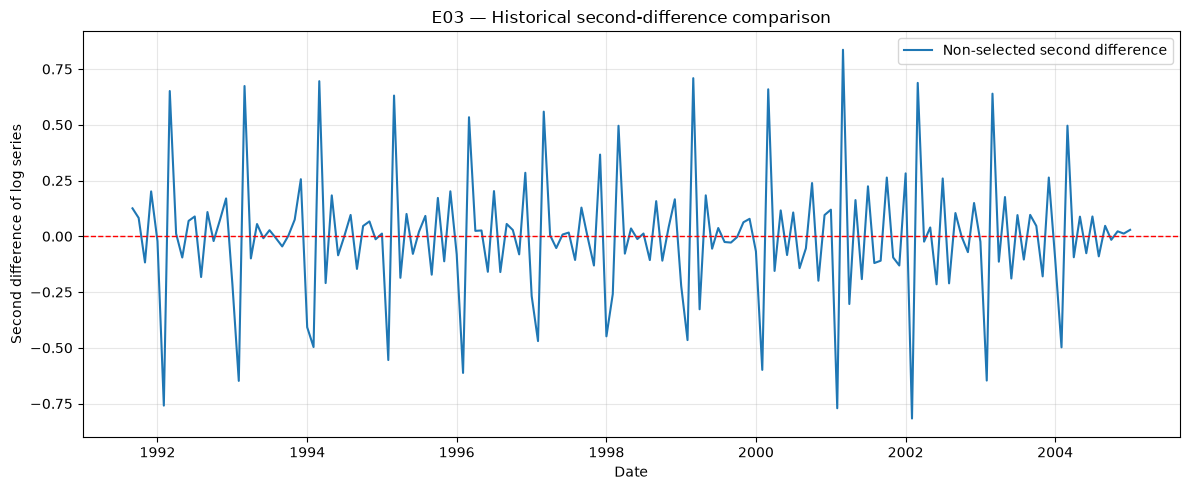

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(second_difference_legacy.index, second_difference_legacy.values, label="Non-selected second difference")
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.title("E03 — Historical second-difference comparison")
plt.xlabel("Date")
plt.ylabel("Second difference of log series")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Kiểm định ADF sau sai phân bậc 2

In [16]:
legacy_adf_note = pd.DataFrame({
    "Item": ["ADF on second difference"],
    "Status": ["Not used for official E03 decision; d=1 is retained"],
})
display(style_table(
    legacy_adf_note,
    caption="E03 — Second-difference ADF is not official evidence",
    row_highlighter=lambda row: ["background-color: #fff4cc; color: #5f4500"] * len(row),
))


Item,Status
ADF on second difference,Not used for official E03 decision; d=1 is retained


### 3. Trạng thái E03

Cell legacy bên trên không thay thế handoff chính thức. Current status ghi nhận log-first-difference trên training scale với `d=1`; reconciliation E03 phải dùng evidence đó.

## 4. E04 — ACF/PACF và ARIMA candidates (reconciliation)

### Vẽ biểu đồ ACF và PACF của chuỗi đã dừng

### Biểu đồ ACF

/Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/src/practice_2/analysis/correlation.py:21: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_values, acf_intervals = acf(series, nlags=nlags, alpha=alpha, fft=True)


lag,correlation,ci_lower,ci_upper,significant
0,1.0000,1.0000,1.0000,True
1,-0.2739,-0.4278,-0.1199,True
2,-0.1412,-0.3063,0.0239,False
3,-0.0190,-0.1870,0.1489,False
4,-0.0600,-0.2280,0.1081,False
5,-0.0293,-0.1978,0.1393,False
6,0.0631,-0.1056,0.2318,False
7,-0.0461,-0.2154,0.1231,False
8,-0.0210,-0.1905,0.1485,False
9,-0.0316,-0.2011,0.1380,False


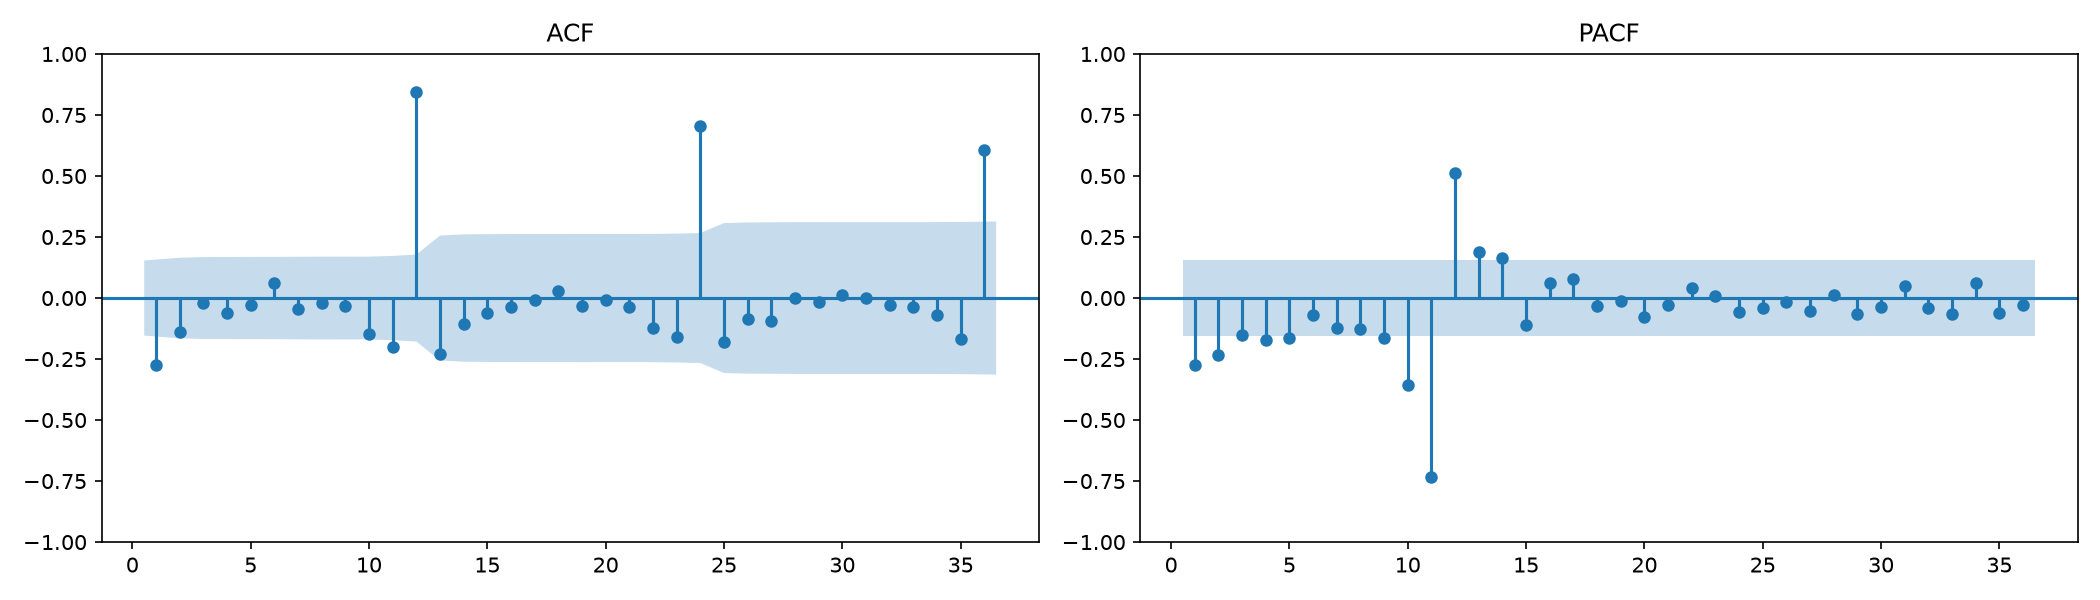

In [17]:
logging.info("E04 ACF/PACF on log-first-difference training series")
acf_table, pacf_table = acf_pacf_tables(log_diff_train, nlags=36)
acf_pacf_path = FIGURES_DIR / "03_acf_pacf_log_first_differenced.png"
save_acf_pacf_plot(log_diff_train, acf_pacf_path, nlags=36, pacf_method="ywm")
display(style_table(
    acf_table,
    caption="E04 — ACF evidence from transformed training series",
    formats={"correlation": "{:.4f}", "ci_lower": "{:.4f}", "ci_upper": "{:.4f}"},
))
display(Image(filename=acf_pacf_path))


Lag 1 có tương quan âm mạnh, có thể phản ánh ảnh hưởng của sai phân hoặc cấu trúc MA.
Các lag 12, 24, 36 nổi bật cách nhau 12 tháng, cho thấy dấu hiệu mùa vụ chu kỳ 12 tháng rất rõ ràng. Vì vậy, dữ liệu này có thể phù hợp với việc xem xét mô hình mùa vụ SARIMA, thay vì chỉ dùng ARIMA thông thường.

#### Biểu đồ PACF

In [18]:
display(style_table(
    pacf_table,
    caption="E04 — PACF evidence from transformed training series",
    formats={"correlation": "{:.4f}", "ci_lower": "{:.4f}", "ci_upper": "{:.4f}"},
))
print("Candidates remain provisional until E05 diagnostics.")


lag,correlation,ci_lower,ci_upper,significant
0,1.0000,1.0000,1.0000,True
1,-0.2739,-0.4278,-0.1199,True
2,-0.2337,-0.3877,-0.0797,True
3,-0.1495,-0.3035,0.0045,False
4,-0.1733,-0.3273,-0.0193,True
5,-0.1655,-0.3195,-0.0115,True
6,-0.0691,-0.2231,0.0849,False
7,-0.1227,-0.2767,0.0313,False
8,-0.1249,-0.2789,0.0291,False
9,-0.1649,-0.3189,-0.0109,True


Candidates remain provisional until E05 diagnostics.


PACF không cắt cụt rõ ràng ngay sau một lag mà có nhiều cột nổi bật. Điều này khiến việc xác định \(p\) chỉ bằng cách đếm cột trở nên khó khăn. Đặc biệt, lag 11 và các lag gần 12 có thể liên quan đến cấu trúc mùa vụ hoặc việc sai phân bậc 2 đã làm thay đổi cấu trúc tương quan.

### Trạng thái E04

Nội dung E04 là reconciliation draft. Candidates chỉ được formalize từ ACF/PACF của transformed training series sau khi upstream evidence được duyệt.

## 5. E05 — Model fitting, diagnostics và forecast evaluation (reconciliation)

### Chia dữ liệu train 80%, test 20%

In [19]:
assert len(train) == 163 and len(test) == 41
assert train.index.max() < test.index.min()
print("E05 evaluation boundary:", len(train), "train /", len(test), "test observations")
print("Test remains sealed until forecast evaluation.")


E05 evaluation boundary: 163 train / 41 test observations
Test remains sealed until forecast evaluation.


### Thiết lập và huấn luyện mô hình

In [20]:
from practice_2.analysis import (
    evaluate_forecast,
    fit_arima,
    forecast_model,
    inverse_log_forecast,
    residual_diagnostics,
    residual_summary,
    seasonal_naive_forecast,
    validate_forecast_alignment,
)
from practice_2.visualization.plots import (
    save_forecast_comparison_plot,
    save_residual_diagnostics_plot,
)


#### Mô hình 1: ARIMA(1,1,1)

In [21]:
result_arima1 = fit_arima(log_train, order=(1, 1, 1))


### Candidate 2 — giữ scope 1–2 models theo đề bài

E05 core chỉ giữ `ARIMA(1,1,1)` và `ARIMA(0,1,1)`. Candidate ARIMA(1,1,0) của exploratory run trước không được dùng trong kết quả formal.


In [22]:
print("ARIMA(1,1,0) không thuộc bộ candidates formal của E05; không fit trong run này.")


ARIMA(1,1,0) không thuộc bộ candidates formal của E05; không fit trong run này.


#### Mô hình 3: ARIMA(0,1,1)

In [23]:
result_arima3 = fit_arima(log_train, order=(0, 1, 1))


### Mô hình SARIMA — không thuộc E05 core

SARIMA được để dành cho E06 trên Dataset 2/AirPassengers. E05 core chỉ fit hai ARIMA candidates theo đề bài.


In [24]:
print("E05 core không fit SARIMA; SARIMA thuộc E06 exploratory extension.")


E05 core không fit SARIMA; SARIMA thuộc E06 exploratory extension.


#### So sánh AIC và BIC

In [25]:
model_orders = {
    "ARIMA(1,1,1)": (1, 1, 1),
    "ARIMA(0,1,1)": (0, 1, 1),
}
models = {
    "ARIMA(1,1,1)": result_arima1,
    "ARIMA(0,1,1)": result_arima3,
}
comparison = pd.DataFrame({
    "Model": list(models),
    "AIC": [result.aic for result in models.values()],
    "BIC": [result.bic for result in models.values()],
    "Decision status": "Candidate fit — diagnostics required",
})
def highlight_candidate(row):
    return ["background-color: #fff4cc; color: #5f4500"] * len(row)
display(style_table(
    comparison.sort_values("AIC"),
    caption="E05 — Two ARIMA candidate comparison on log training levels",
    formats={"AIC": "{:.2f}", "BIC": "{:.2f}"},
    row_highlighter=highlight_candidate,
))


Model,AIC,BIC,Decision status
"ARIMA(1,1,1)",-131.05,-121.79,Candidate fit — diagnostics required
"ARIMA(0,1,1)",-120.45,-114.27,Candidate fit — diagnostics required


In [26]:
best_name = min(models, key=lambda name: models[name].aic)
best_result = models[best_name]
residuals = pd.Series(best_result.resid, index=log_train.index).dropna()
residual_details = residual_summary(residuals)
display(style_table(
    residual_details,
    caption=f"E05 — Residual summary for AIC-leading candidate ({best_name})",
    formats={"value": "{:.6f}"},
))


metric,value
residual_mean,0.044193
n_observations,163.000000


Trong các mô hình được ước lượng trên cùng dữ liệu, AIC/BIC thấp hơn thường là dấu hiệu tốt hơn. Tuy nhiên, đừng chọn mô hình chỉ dựa vào hai chỉ số này; cần kiểm tra phần dư và dự báo trên tập test.

#### Vẽ phần dư theo thời gian và ACF của phần dư

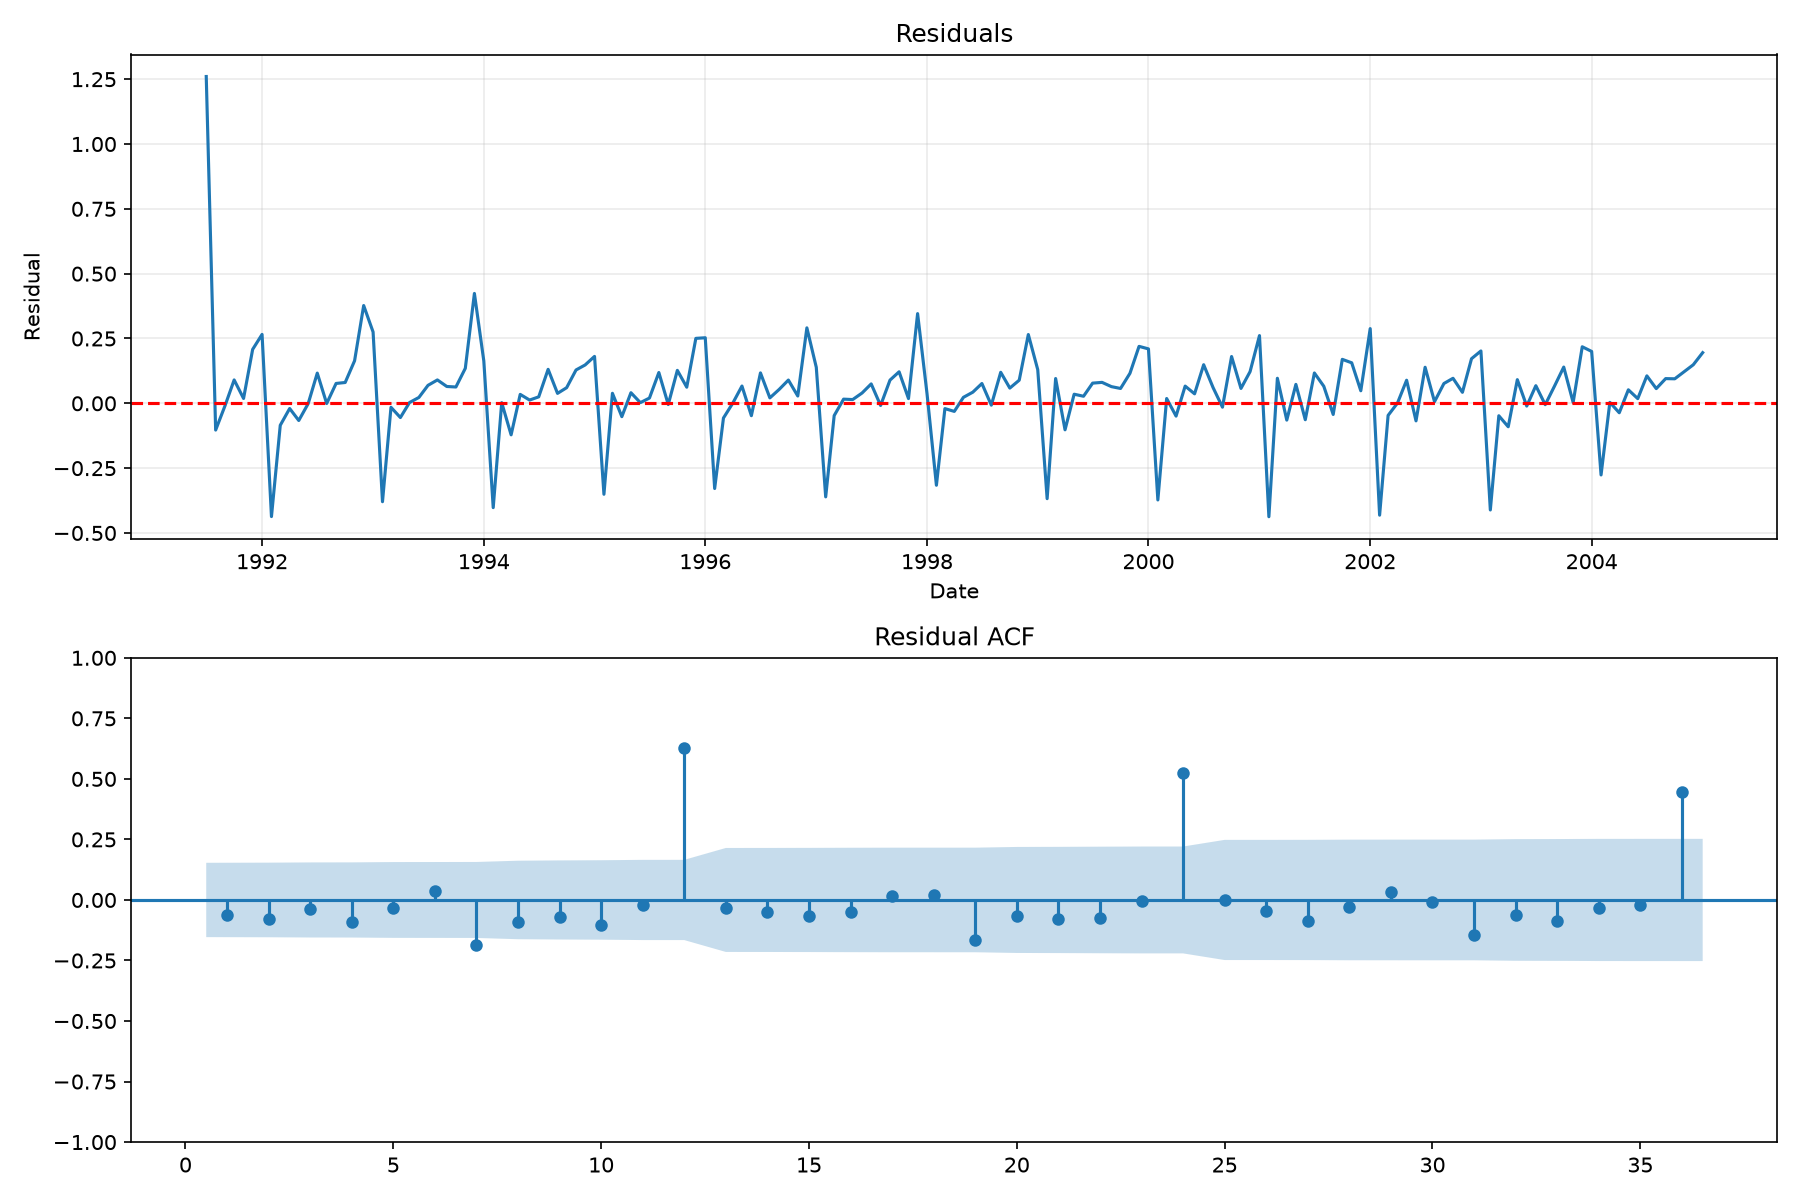

,metric,value
0,residual_mean,0.044193
1,n_observations,163.000000


In [27]:
logging.info(f"Bắt đầu phân tích phần dư cho mô hình {best_name}.")
residual_plot_path = FIGURES_DIR / "05_residual_diagnostics_log_d1.png"
save_residual_diagnostics_plot(residuals, residual_plot_path, nlags=36)
display(Image(filename=residual_plot_path))
display(residual_details)
logging.info(f"Đã hoàn thành residual diagnostics cho mô hình {best_name}.")

Residual interpretation của reconciliation candidate chưa phải formal completion evidence. Ljung–Box vẫn phải được dùng để đánh giá white-noise claim.


#### **Kiểm tra bằng Ljung–Box**

In [28]:
model_df = model_orders[best_name][0] + model_orders[best_name][2]
ljung_box_result = residual_diagnostics(residuals, lags=(12, 24), model_df=model_df)
ljung_display = ljung_box_result.assign(**{"Decision status": "Inspect p-value; no automatic model selection"})
display(style_table(
    ljung_display,
    caption="E05 — Ljung–Box residual diagnostic",
    formats={"lb_stat": "{:.3f}", "lb_pvalue": "{:.4f}", "alpha": "{:.2f}"},
    row_highlighter=highlight_candidate,
))


lag,lb_stat,lb_pvalue,alpha,decision,Decision status
12,84.704,0.0000,0.05,reject white noise,Inspect p-value; no automatic model selection
24,147.850,0.0000,0.05,reject white noise,Inspect p-value; no automatic model selection


#### Dự đoán trên tập test

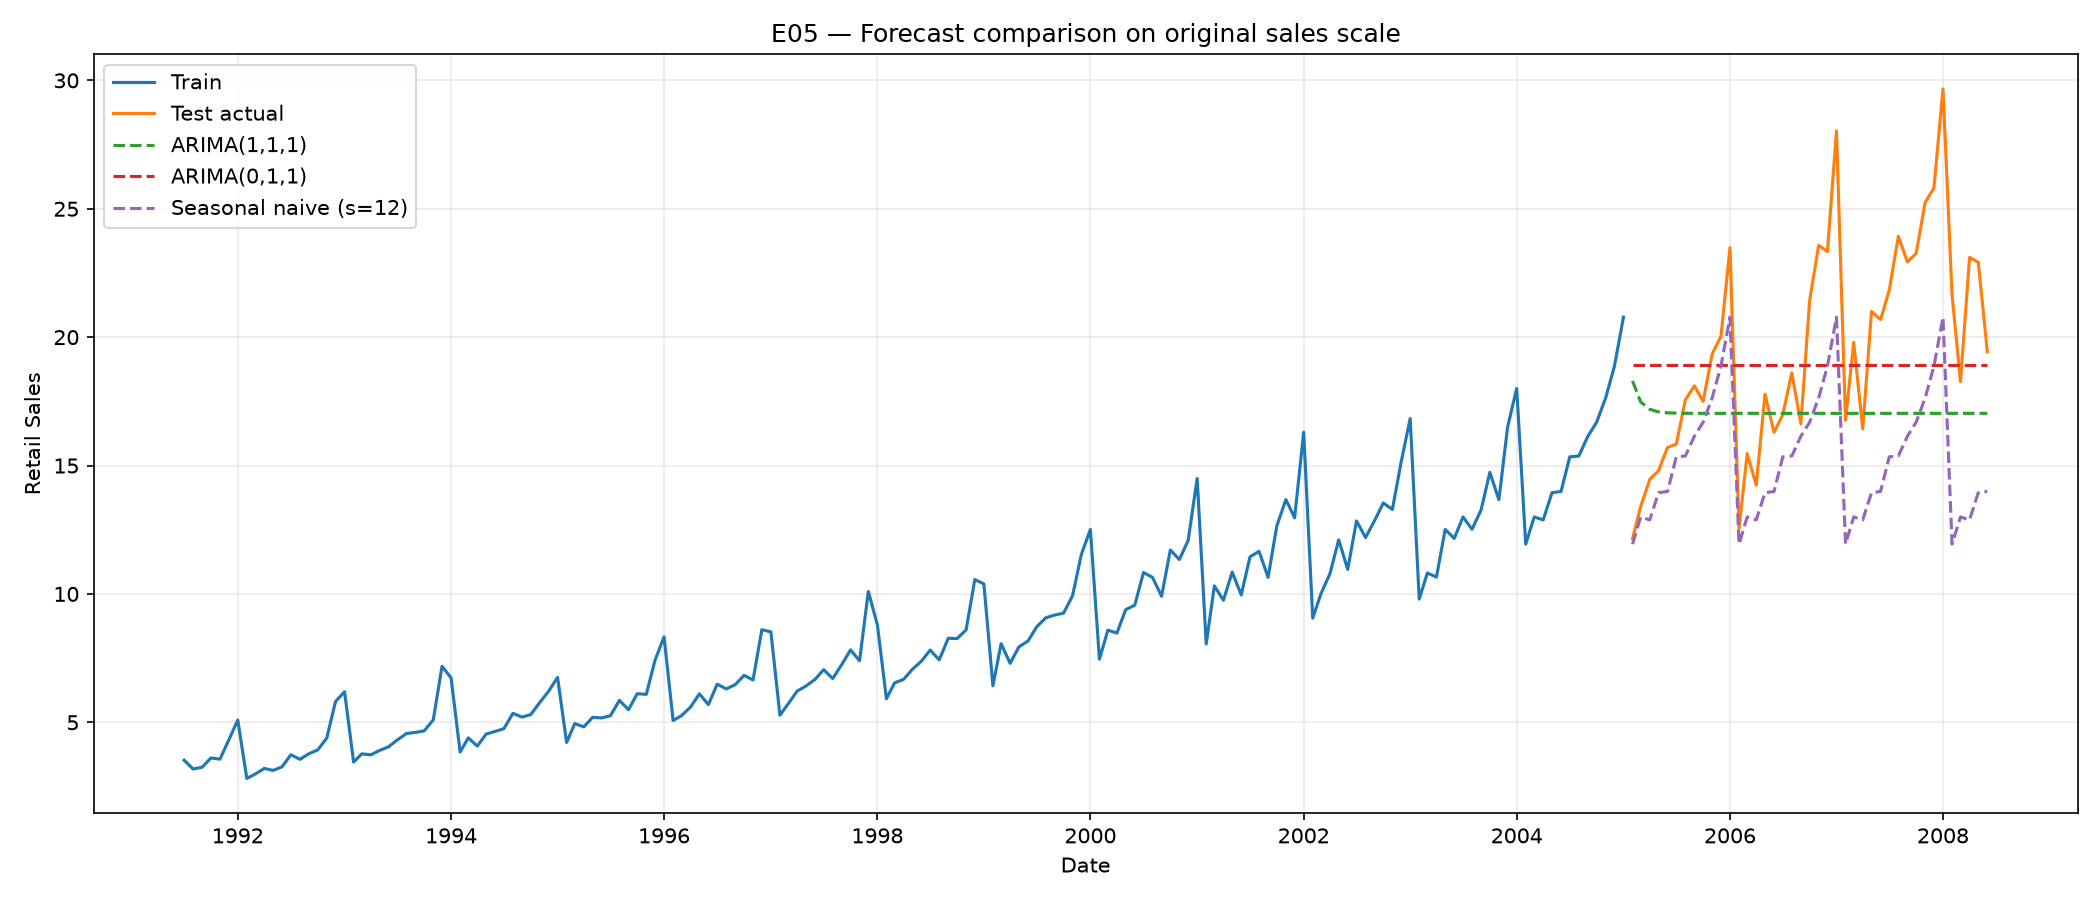

In [29]:
log_forecasts = {
    name: forecast_model(result, test.index, name)
    for name, result in models.items()
}
forecasts = {
    name: inverse_log_forecast(forecast)
    for name, forecast in log_forecasts.items()
}
forecasts["Seasonal naive (s=12)"] = seasonal_naive_forecast(train, test.index, seasonal_period=12)
for forecast in forecasts.values():
    validate_forecast_alignment(test, forecast)
assert all(len(forecast) == 41 for forecast in forecasts.values())
forecast_plot_path = FIGURES_DIR / "05_forecast_comparison_log_d1.png"
save_forecast_comparison_plot(
    train,
    test,
    forecasts,
    forecast_plot_path,
    title="E05 — Forecast comparison on original sales scale",
    ylabel="Retail Sales",
)
display(Image(filename=forecast_plot_path))


#### Đánh giá mô hình bằng MAE, RMSE, MAPE

In [30]:
evaluation = []
for name, forecast in forecasts.items():
    metric_table = evaluate_forecast(test, forecast)
    metrics = dict(zip(metric_table["metric"], metric_table["value"]))
    evaluation.append({"Model": name, **metrics})
evaluation_df = pd.DataFrame(evaluation)
evaluation_df["Decision status"] = "Candidate — review diagnostics"
evaluation_df.loc[evaluation_df["Model"] == "Seasonal naive (s=12)", "Decision status"] = "Baseline reference"
def highlight_evaluation(row):
    if row["Decision status"] == "Baseline reference":
        return ["background-color: #dbeafe; font-weight: 600"] * len(row)
    return ["background-color: #fff4cc; color: #5f4500"] * len(row)
display(style_table(
    evaluation_df.sort_values("RMSE"),
    caption="E05 — 41-month holdout metrics on original sales scale",
    formats={"MAE": "{:.2f}", "RMSE": "{:.2f}", "MAPE": "{:.2f}%"},
    row_highlighter=highlight_evaluation,
))
logging.info("E05 complete | horizon=41 | baseline=seasonal_naive_12 | test_used=true")


Model,MAE,RMSE,MAPE,Decision status
"ARIMA(0,1,1)",3.47,4.18,18.17%,Candidate — review diagnostics
"ARIMA(1,1,1)",3.83,4.87,18.49%,Candidate — review diagnostics
Seasonal naive (s=12),4.26,5.19,20.10%,Baseline reference


| Chỉ số  | Ý nghĩa   | Tốt hơn khi               |
| ---     | ---       | ---                       |
| **MAE** | Sai số tuyệt đối trung bình           | Thấp hơn
| **RMSE** | Phạt mạnh hơn các sai số lớn         | Thấp hơn
| **MAPE** | Sai số phần trăm tuyệt đối trung bình| Thấp hơn


Metrics đã được chạy lại theo train-only/41-month protocol; E05 vẫn ở reconciliation cho đến khi approval state được cập nhật.

### Trạng thái E05

E05 đang reconciliation. Notebook không claim model hoàn thành hoặc superior cho đến khi scientific protocol, baseline, aligned forecast và diagnostics được formal validation.

# Model Summary

In [31]:
summary_text = best_result.summary().as_text()
summary_path = PROJECT_ROOT / "outputs" / "results" / "Model_Summary_Prac2_Exercise.txt"
with open(summary_path, "w", encoding="utf-8") as file:
    file.write("MODEL SUMMARY\n")
    file.write(f"Model: {best_name}\n")
    file.write("=" * 80 + "\n\n")
    file.write(summary_text)
print("Đã lưu Model Summary:", summary_path)
logging.info(f"Đã lưu Model Summary | Model: {best_name} | File: {summary_path}")

Đã lưu Model Summary: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/outputs/results/Model_Summary_Prac2_Exercise.txt
